# Alignment quality of the unmasked chr22 alignments

Sum-of-pairs score (cogent3 `sp_score`) in non-overlapping 1 kb windows of the
`singlent_nomasked.fa` alignments written by `filtering_masked_nointrons.py`, for
`intergenicAR`, `intronsAR` and `distalIG`. The three per-window distributions are
overlaid in one histogram.

`sp_score` turns each pairwise genetic distance into an estimated number of
unchanged positions, subtracts an affine gap penalty (`gap_insert=12`, `gap_extend=1`
by default), and sums over the three species pairs. With 3 sequences and a 1 kb
window the maximum is 3000 (three identical, gap-free sequences); gap-dominated
windows go strongly negative.

**Caveat on these files.** 59-69% of the columns in each `singlent_nomasked.fa` are
gaps in all three species (see the `frac_allgap_cols` column below). Such columns
cannot occur in a real alignment, and `sp_score` simply skips them (they contribute
to neither the pairwise distances nor the gap penalties), so a raw 1 kb window of
the file holds anywhere between 0 and 1000 scorable columns and all-gap windows
score exactly 0. With `DROP_ALLGAP_COLUMNS = True` the all-gap columns are removed
with `omit_gap_pos()` before windowing, so every window is 1 kb of columns where at
least one species has a base. Set it to `False` to see the raw file.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cogent3 import load_aligned_seqs, get_app

import paths

In [2]:
REGIONS = ["intergenicAR", "intronsAR", "distalIG"]
LABEL = "singlent_nomasked"
WINDOW = 1_000  # bp
DROP_ALLGAP_COLUMNS = True  # remove columns that are '-' in every species before windowing

# default sp_score settings; calc="pdist" avoids NaN distances on very divergent windows
sp_score = get_app("sp_score", calc="JC69", gap_insert=12.0, gap_extend=1.0)

In [3]:
def window_sp_scores(aln, window, app):
    """sp_score for each non-overlapping window of `window` columns.

    The trailing partial window is dropped so every score is on the same
    number of columns. Windows the app cannot score (NotCompleted) are
    counted and excluded.
    """
    scores, failed = [], 0
    for start in range(0, len(aln) - window + 1, window):
        result = app(aln[start : start + window])
        if isinstance(result, float):
            scores.append(result)
        else:
            failed += 1
    return np.array(scores), failed

In [4]:
scores = {}
summary = []
for region in REGIONS:
    fname = paths.DATA_HUMCHIMPORANGOR114 + region + "/chrm22/" + LABEL + ".fa"
    raw = load_aligned_seqs(fname, moltype="dna")
    # default allowed_gap_frac drops only columns that are gaps in every sequence
    aln = raw.omit_gap_pos() if DROP_ALLGAP_COLUMNS else raw
    scores[region], failed = window_sp_scores(aln, WINDOW, sp_score)
    s = scores[region]
    summary.append(
        {
            "region": region,
            "file_length": len(raw),
            "frac_allgap_cols": 1 - len(raw.omit_gap_pos()) / len(raw),
            "scored_length": len(aln),
            "n_windows": len(s),
            "failed_windows": failed,
            "mean": s.mean(),
            "median": np.median(s),
            "q05": np.quantile(s, 0.05),
            "q95": np.quantile(s, 0.95),
            "frac_negative": (s < 0).mean(),
        }
    )

summary = pd.DataFrame(summary).set_index("region")
summary

,file_length,frac_allgap_cols,scored_length,n_windows,failed_windows,mean,median,q05,q95,frac_negative
region,,,,,,,,,,
intergenicAR,8844979,0.604815,3495406,3494,1,1149.268831,2304.771752,-3106.2,2849.497516,0.263309
intronsAR,20316665,0.589188,8346334,8346,0,1490.216871,2411.184289,-2138.0,2848.112554,0.200216
distalIG,3690895,0.686986,1155301,1155,0,2062.938656,2703.663145,-2024.0,2893.851146,0.114286


The regions differ ~5x in length, so the histograms are drawn as densities on a
shared set of bins; otherwise `intronsAR` would swamp the other two.

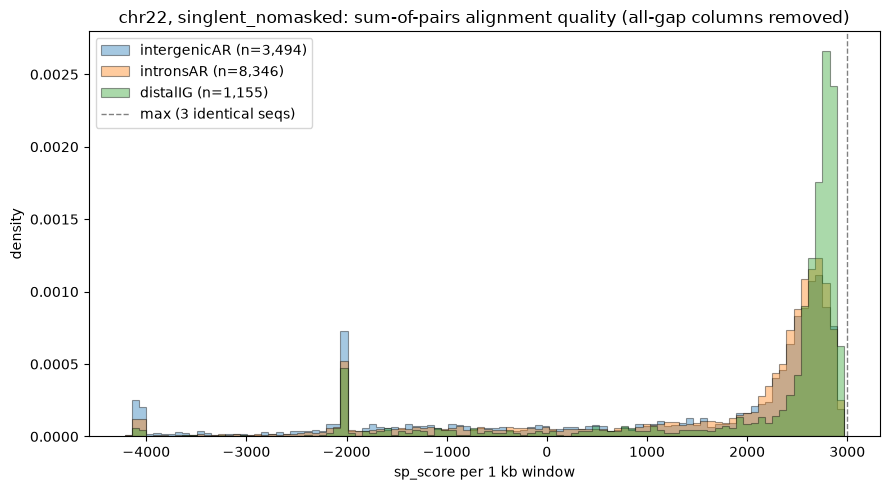

In [5]:
all_scores = np.concatenate(list(scores.values()))
bins = np.linspace(all_scores.min(), all_scores.max(), 101)

fig, ax = plt.subplots(figsize=(9, 5))
for region in REGIONS:
    ax.hist(
        scores[region],
        bins=bins,
        density=True,
        histtype="stepfilled",
        alpha=0.4,
        edgecolor="black",
        linewidth=0.8,
        label=f"{region} (n={len(scores[region]):,})",
    )
ax.axvline(3 * WINDOW, color="grey", linestyle="--", linewidth=1, label="max (3 identical seqs)")
ax.set_xlabel(f"sp_score per {WINDOW // 1000} kb window")
ax.set_ylabel("density")
ax.set_title(
    "chr22, singlent_nomasked: sum-of-pairs alignment quality"
    + (" (all-gap columns removed)" if DROP_ALLGAP_COLUMNS else " (raw file)")
)
ax.legend()
fig.tight_layout()
fig.savefig("output_data/alignment_quality_sp_score_1kb.png", dpi=150)
plt.show()

Same data on a log-scaled y axis, which makes the long negative (gap-rich) tail visible.

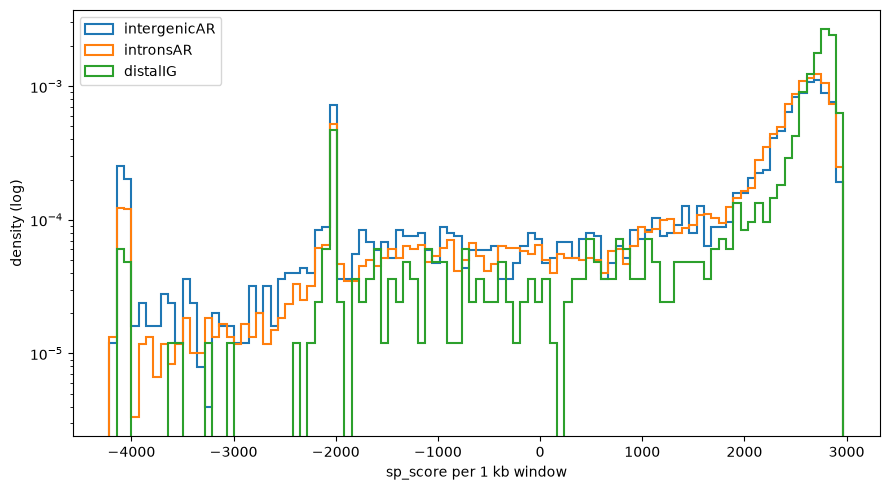

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for region in REGIONS:
    ax.hist(scores[region], bins=bins, density=True, histtype="step", linewidth=1.5, label=region)
ax.set_yscale("log")
ax.set_xlabel(f"sp_score per {WINDOW // 1000} kb window")
ax.set_ylabel("density (log)")
ax.legend()
fig.tight_layout()
plt.show()